# Ingestion — what is in `data/final/`, and how complete it is

**What this notebook does.** Looks at the tables the ingestion step built from 911records.org and the City portal: what each table holds, whether our copy is complete, what the archive consists of, and which of the site's fields can be used as they are. It does not scrape anything; it reads the committed tables (`git lfs pull`).

**Where things are.** How the scrape works, how to run it, files and checks: [`src/ingestion/README.md`](../src/ingestion/README.md). Findings, known issues and the full data dictionary: [`docs/00.ingestion_report.md`](../docs/00.ingestion_report.md). Next step: [`01.process_pipeline.ipynb`](01.process_pipeline.ipynb).

**Contents.** 1 The tables · 2 Look up one document · 3 Is our copy complete? · 4 Whose files · 5 Text · 6 The site's metadata · 7 Building links · 8 Catalog changes and ID-only documents · 9 Verification · 10 Summary

In [1]:
import os
from pathlib import Path
if Path.cwd().name == "notebooks":          # run from the repo root so `src` and `data/` resolve
    os.chdir(Path.cwd().parent)
import json
import pandas as pd
from IPython.display import Image, display
import config
from src.ingestion import figures, verify
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 90); pd.set_option("display.max_columns", 25)
F = config.FINAL
print("working dir:", Path.cwd().name)

working dir: latest


## 1. The tables

Seven Parquet tables, joined by `doc_id` + `page`, `entity_type` + `slug`, and `bin`. `verify.load()` stops with a clear message if the files are still Git LFS pointers.

In [2]:
t = verify.load()
documents = pd.read_parquet(F / "documents.parquet")
pages = pd.read_parquet(F / "pages.parquet")            # with text (~1 GB in memory)
entities, mentions = t["entities"], pd.read_parquet(F / "entity_mentions.parquet")
buildings, building_mentions, changes = t["buildings"], t["building_mentions"], t["catalog_changes"]

overview = pd.DataFrame({name: {"rows": len(df), "columns": df.shape[1]} for name, df in
                         {"documents": documents, "pages": pages, "entities": entities, "entity_mentions": mentions,
                          "buildings": buildings, "building_mentions": building_mentions,
                          "catalog_changes": changes}.items()}).T
overview

1. 7 tables loaded: documents 64,619, pages 230,888, entities 15,915, entity_mentions 650,196, buildings 984, building_mentions 16,151, catalog_changes 794


,rows,columns
documents,64619,23
pages,230888,14
entities,15915,8
entity_mentions,650196,7
buildings,984,23
building_mentions,16151,4
catalog_changes,794,4


In [3]:
# every column: share filled in, distinct values, an example (data dictionary: report Appendix A)
def profile(df):
    out = []
    for c in df.columns:
        s = df[c]
        filled = s.notna() & ~s.astype(str).isin(["[]", ""])
        out.append({"column": c, "dtype": str(s.dtype), "filled": f"{filled.mean():.1%}",
                    "distinct": s.astype(str).nunique(), "example": str(s[filled].iloc[0])[:60] if filled.any() else ""})
    return pd.DataFrame(out).set_index("column")

profile(documents)

,dtype,filled,distinct,example
column,,,,
doc_id,str,100.0%,64619,NYC-WTC_000000001
bates_start,int64,100.0%,64619,1
bates_range,str,99.6%,64385,NYC-WTC_000000001–000000009
n_pages,float64,99.6%,204,9.0
file_size,str,99.6%,7467,9 pages / 8.2 MB
collection,str,37.8%,3,DEP Hard Copies (68 Boxes)
agency,str,99.6%,23,"Environmental Protection, Dept. of"
production_volume,str,99.6%,9,NYC-WTC0001
box,str,37.8%,114,DEP Box 04


In [4]:
profile(pages.drop(columns="text"))

,dtype,filled,distinct,example
column,,,,
doc_id,str,100.0%,64385,NYC-WTC_000125674
page,int64,100.0%,620,1
source,str,100.0%,3,pdftotext
ocr_confidence,float64,0.4%,866,42.7570554625
bates_page,str,100.0%,230888,NYC-WTC_000125674
date,datetime64[us],85.9%,1799,2005-02-17 00:00:00
date_source,str,100.0%,2,none
url,str,100.0%,230888,https://911records.org/doc/NYC-WTC_000125674
contaminants,object,43.7%,2367,['lead']


**Reading.** Most columns are filled for every scraped document. The exceptions are the subject of sections 6–8: `title_confidence`, `doc_type` and `doc_type_confidence` are empty, `removed_date` is empty, `box` and `collection` cover 38%, `site_date` 79%, and on pages `entity_links` is always `[]` and `ocr_confidence` exists only where our OCR ran.

## 2. Look up one document

Everything the tables hold about one document: its metadata, its pages, and the entities and buildings linked to them. Change `doc_id` to look up another.

In [5]:
def lookup(doc_id):
    doc = documents.set_index("doc_id").loc[doc_id]
    print(f"{doc_id} · {doc['title']}\n  agency: {doc['agency']} · box: {doc['box']} · folder: {doc['folder']}"
          f" · site_date: {doc['site_date']} · {doc['n_pages']:.0f} pages\n  {doc['url']}")
    p = pages[pages["doc_id"] == doc_id][["page", "bates_page", "source", "ocr_status", "contaminants", "building_bins"]]
    ents = (mentions[mentions["doc_id"] == doc_id].merge(entities[["entity_type", "slug", "name"]])
            .groupby(["entity_type", "name"])["page"].agg(lambda s: sorted(set(s))).reset_index())
    blds = building_mentions[building_mentions["doc_id"] == doc_id].merge(buildings[["bin", "name"]])[["bin", "name", "page"]]
    return p, ents, blds

p, ents, blds = lookup("NYC-WTC_000092966")
display(p.head(10)); display(ents.head(15)); display(blds)
print(pages.loc[pages["doc_id"] == "NYC-WTC_000092966", "text"].iloc[0][:600])

NYC-WTC_000092966 · Athenica airborne asbestos analysis report, September 2002
  agency: Environmental Protection, Dept. of · box: DEP Box 01 · folder: “44 JOHN STREET 1001110, 67/30” · site_date: 2002-09-14 00:00:00 · 2 pages
  https://911records.org/doc/NYC-WTC_000092966


,page,bates_page,source,ocr_status,contaminants,building_bins
50011,1,NYC-WTC_000092966,pdftotext,ok,[asbestos],"[""1001110""]"
50012,2,NYC-WTC_000092967,pdftotext,ocr,[],"[""1001110""]"


,entity_type,name,page
0,address,44 Jolsl Street,[1]
1,agency,DEP,[1]
2,agency,EPA,[2]
3,contractor,Atheniea Pnvirenmentel Senices Inc.,[1]
4,substance,Asbestos,[1]


,bin,name,page
0,1001110,44 John Street,1


NYC 9/11 Public Portal Document

AIRBORNE ASBESTOS ANALYSIS BY TRANSMISSION ELECTRON MICROSCOPY
PROJECT_ NYC DEP, 44 Jolsl Street
DATE OF REPORT: 09/14/02
DATE OF ANALYSYS:09114/02
EFFF.CUVE FILTER AREA (mm 385

CLIENT. Warren & Pe r Engineers, P.C.
LA110RATORY a'/: T02-09-044
ANALYT.METHODOLOGY: AHERA
VILTER TYPE: M.C.F..
AVRRAGF G.0. AREA. (mm2): 0.013771
m

ATHENICA
EIMROudAt9fTALSOMICES INC.
Tel. 4710) 704.7490
Fs. (710) 764-40hi3

LABORATORY RESULT'S
CLIENT
8

01
02
03
04
05

[B.
A3BEST. F A11
ASSEST
'TYPE
CHRYS.
TYPE
SPECIFY

VOLUME
(ii)

G.O.'s
ANAL
V7'.PA

AREA
A(YAI Y
ZRI)
(rntn')

M4


**Reading.** One document, joined across the tables by `doc_id` and `page`: the page-level contaminant and building tags, the entities the site links to each page, and the building from `building_mentions`. The entity names come from the scanned text, so they are spelled as scanned ("Atheniea Pnvirenmentel Senices Inc.", "44 Jolsl Street"); processing merges some variants, not OCR misspellings.

## 3. Is our copy complete?

The checks behind the report's section 4.1: keys, every page of every document, consistent Bates numbers, every link joins, and our entity links against the site's own page counts.

In [6]:
verify.check_keys(t)
verify.check_completeness(t)
verify.check_joins(t)
verify.check_entity_counts(t)
per_doc = pages.groupby("doc_id").size()
print(f"pages per document: mean {per_doc.mean():.1f}, median {per_doc.median():.0f}, max {per_doc.max()}; "
      f"{(per_doc == 1).sum():,} single-page documents")

2. keys unique and well formed (doc_id, (doc_id, page), (entity_type, slug), bin)


3. all 64,385 scraped documents have all their pages (230,888), numbered 1..n, with consistent Bates page numbers


4. every entity mention (650,196) and building mention (16,151) joins to its entity or building and to an existing page
5. entity mentions per entity equal the site's n_pages for 15,583 of 15,586 entities (exceptions: 3 'Page Avenue' addresses)
pages per document: mean 3.6, median 1, max 620; 43,174 single-page documents


In [7]:
# the 3 entities whose site count differs from our links
ours = mentions.groupby(["entity_type", "slug"]).size().rename("our_links")
cmp = entities.set_index(["entity_type", "slug"])[["name", "n_pages"]].join(ours).fillna({"our_links": 0})
cmp[(cmp["n_pages"] != cmp["our_links"]) & (cmp.index.get_level_values(0) != "building")]

name  n_pages  our_links
entity_type slug                                                
address     25-page-avenue    25 Page Avenue       25        2.0
            527-page-avenue  527 Page Avenue      527        2.0
            555-page-avenue  555 Page Avenue      555        1.0

**Reading.** All 64,385 scraped documents have all their pages (230,888), every link joins, and our entity links equal the site's count for 15,583 of 15,586 entities. The three exceptions are "Page Avenue" addresses, whose site count is the house number. The 234 document IDs without pages are explained in section 8.

## 4. Whose files

In [8]:
docs = verify.scraped(documents)
by_agency = pd.DataFrame({
    "documents": docs["agency"].value_counts(),
    "pages": pages[["doc_id"]].merge(docs[["doc_id", "agency"]])["agency"].value_counts(),
}).fillna(0).astype(int).sort_values("pages", ascending=False)
by_agency["% documents"] = (by_agency["documents"] / by_agency["documents"].sum() * 100).round(1)
by_agency["% pages"] = (by_agency["pages"] / by_agency["pages"].sum() * 100).round(1)
by_agency["pages per document"] = (by_agency["pages"] / by_agency["documents"]).round(1)
print(f"{len(by_agency)} agencies")
by_agency.head(8)

23 agencies


,documents,pages,% documents,% pages,pages per document
agency,,,,,
"Environmental Protection, Dept. of",24705,171641,38.4,74.3,6.9
"Education, Dept. of",33765,41619,52.4,18.0,1.2
"Citywide Administrative Services, Dept. of",3014,7400,4.7,3.2,2.5
"Design and Construction, Dept. of",1207,2611,1.9,1.1,2.2
"Records and Information Services, Dept. of",27,2102,0.0,0.9,77.9
"Health and Mental Hygiene, Dept. of",371,1610,0.6,0.7,4.3
Fire Department,276,1418,0.4,0.6,5.1
Law Department,323,561,0.5,0.2,1.7


In [9]:
edu = docs[docs["agency"] == "Education, Dept. of"]
print(f"Education documents: {len(edu):,}, {(edu['n_pages'] == 1).mean():.0%} one page; most common titles:")
print(edu["title"].str.replace(r",? ?(\w+ )?\d{4}$", "", regex=True).value_counts().head(8).to_string())
print("\nfiling: documents with a box", f"{docs['box'].notna().sum():,}", "· by collection:")
print(docs["collection"].fillna("(none)").value_counts().to_string())
print("\nproduction volumes:", docs["production_volume"].value_counts().sort_index().to_dict())

Education documents: 33,765, 94% one page; most common titles:
title
TEM asbestos air count sheet                         992
TEM asbestos air count sheet, lab                    523
TEM Asbestos air sample results, NYC BOE             201
TEM asbestos air sample results, NYC BOE              59
Chain of custody form, PSC Analytical Services        42
TEM asbestos air count sheet, NYC BOE                 26
TEM Asbestos air sample results, NYC BOE, Feb         25
Chain of custody form for PSC Analytical Services     24

filing: documents with a box 24,427 · by collection:
collection
(none)                        39939
DEP Hard Copies (68 Boxes)    21392
WTC 7                          3027
DORIS Giuliani                   27

production volumes: {'NYC-WTC0001': 133, 'NYC-WTC0002': 4998, 'NYC-WTC0003': 3355, 'NYC-WTC0004': 7212, 'NYC-WTC0005': 19, 'NYC-WTC0006': 4920, 'NYC-WTC0007': 2991, 'NYC-WTC0008': 39939, 'NYC-WTC0010': 818}


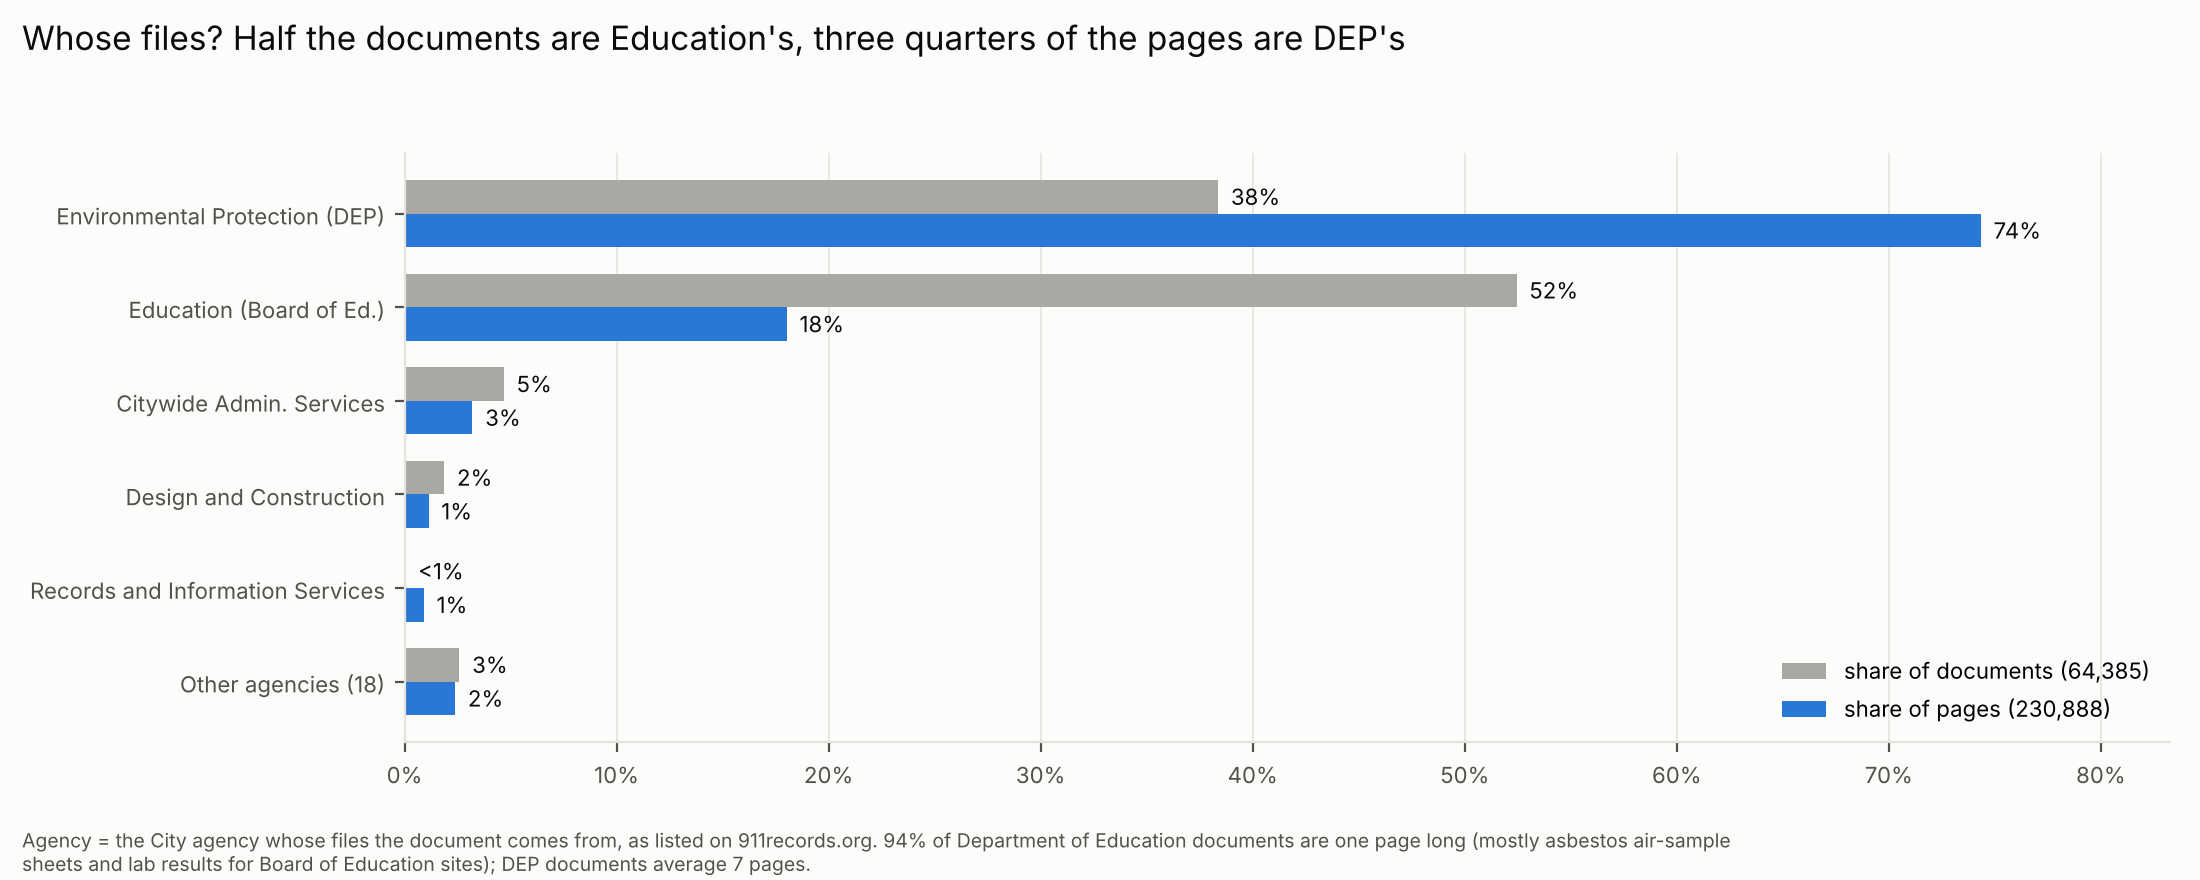

In [10]:
display(Image(str(figures.whose_files_figure(documents, pages[["doc_id", "page"]]))))

**Reading.** By documents, the archive is mostly the Department of Education's (52%): one-page TEM asbestos air-count sheets and sample results. By pages, it is mostly DEP's (74%), whose documents average 7 pages. Archive-wide counts are first counts over these two agencies' files, and pages and documents give different pictures. Only 38% of documents keep a box and collection; the largest production volume (NYC-WTC0008, all the Education documents) has none.

## 5. Text

In [11]:
print(pages["source"].value_counts().to_string())
print(f"\nOCR'd pages: median word confidence {pages['ocr_confidence'].median():.0f} / 100")
print(f"pages with the portal header: {pages['text'].str.contains('NYC 9/11 Public Portal Document', regex=False).mean():.1%}")
pd.crosstab(pages["ocr_source"], pages["ocr_status"], margins=True)

source
pdftotext    230022
tesseract       865
none              1

OCR'd pages: median word confidence 75 / 100
pages with the portal header: 95.7%


ocr_status,empty,junk,ocr,ok,All
ocr_source,,,,,
ours,2,0,10232,0,10234
pdftotext,2112,3982,0,214560,220654
All,2114,3982,10232,214560,230888


**Reading.** 99.6% of pages come from the PDF's own text layer; 865 image-only pages were read with Tesseract; one page has no text, and the site fallback was never needed. Almost every page carries the portal header and stamps, which processing removes. The site's `ocr_status` and `ocr_source` describe the site's own OCR (`ours` = the site's), not how usable the text is.

## 6. The site's metadata

In [12]:
sd = docs["site_date"]
print(f"site_date missing: {sd.isna().sum():,} of {len(docs):,} ({sd.isna().mean():.0%})")
print("before 1900:", sd[sd < "1900"].dt.year.value_counts().to_dict(), "· after 2015:", sd[sd > "2015-12-31"].dt.date.tolist())
print("most common years:", sd.dt.year.value_counts().head(6).astype(int).to_dict())
print("page date_source:", pages["date_source"].value_counts().to_dict())
print("doc_type values:", docs["doc_type"].dropna().str[:40].tolist())

site_date missing: 13,154 of 64,385 (20%)
before 1900: {1: 39, 200: 1} · after 2015: [datetime.date(2019, 5, 28)]
most common years: {2002.0: 38205, 2001.0: 9217, 1998.0: 1122, 2003.0: 848, 1999.0: 536, 1994.0: 198}
page date_source: {'document': 198427, 'none': 32461}
doc_type values: ['M.C.E.', 'O Prints O Sepia O Specifications O Shop', "3 3 Fl ?SD/ '0/13-/ 38f 5S 2^ W llP ZSI "]


In [13]:
from collections import Counter
tags = Counter(x for row in pages["contaminants"] for x in row)
print(f"pages with contaminant tags: {(pages['contaminants'].map(len) > 0).sum():,} · distinct terms: {len(tags)}")
print(tags.most_common(8))
pd.DataFrame({"entities": entities["entity_type"].value_counts(), "page links": mentions["entity_type"].value_counts()}).fillna(0).astype(int)

pages with contaminant tags: 100,826 · distinct terms: 53
[('asbestos', 62777), ('chrysotile', 35843), ('amosite', 35264), ('particulate', 35058), ('actinolite', 34578), ('crocidolite', 34542), ('anthophyllite', 34311), ('tremolite', 31309)]


,entities,page links
entity_type,,
address,6427,68235
agency,46,99268
building,329,0
contractor,6256,41785
lab,1136,24158
signatory,1668,4610
substance,53,412140


**Reading.** `site_date` is missing for 20% of documents and includes impossible dates (year 1, 2019); it is the earliest date anywhere in the text, which processing corrects with the title. Pages never have their own date. `doc_type` is effectively empty, so there is no ready-made label for memos versus forms. Contaminant tags cover 44% of pages, dominated by asbestos and its fiber types; substances are also 63% of all entity links. The 329 "building" entities have no page links (buildings come through their own tables).

## 7. Building links

The site links buildings to pages twice: on each building's page (→ `building_mentions`) and on each document page (→ `pages.building_bins`). Below: both against the site's own page count per building.

In [14]:
cov = verify.building_coverage(t)
print(cov.groupby("kind")[["site_count", "building_mentions", "page_tags"]].sum())
short = cov[(cov["kind"] == "bin") & (cov["building_mentions"] < cov["site_count"])]
print(f"\nBIN buildings where building_mentions has fewer pages than the site: {len(short)} of {(cov['kind'] == 'bin').sum()}")
cov.sort_values("site_count", ascending=False).head(8)

      site_count  building_mentions  page_tags
kind                                          
bbl         1843               2296          0
bin        20115              13855      23744

BIN buildings where building_mentions has fewer pages than the site: 291 of 846


,name,kind,record_type,site_count,building_mentions,page_tags
bin,,,,,,
1001410,120 Church Street,bin,test,534,194,539
1001650,105 Duane Street,bin,test,482,291,736
1083378,365 SOUTH END AVENUE,bin,test,444,71,530
bbl:1000160100,345 South End Avenue,bbl,test,414,19,0
1083375,375 SOUTH END AVENUE,bin,test,355,88,416
1083239,40 HARRISON STREET,bin,test,355,102,383
1001003,72 Wall Street,bin,test,344,79,347
1001230,90 Church Street,bin,test,318,35,328


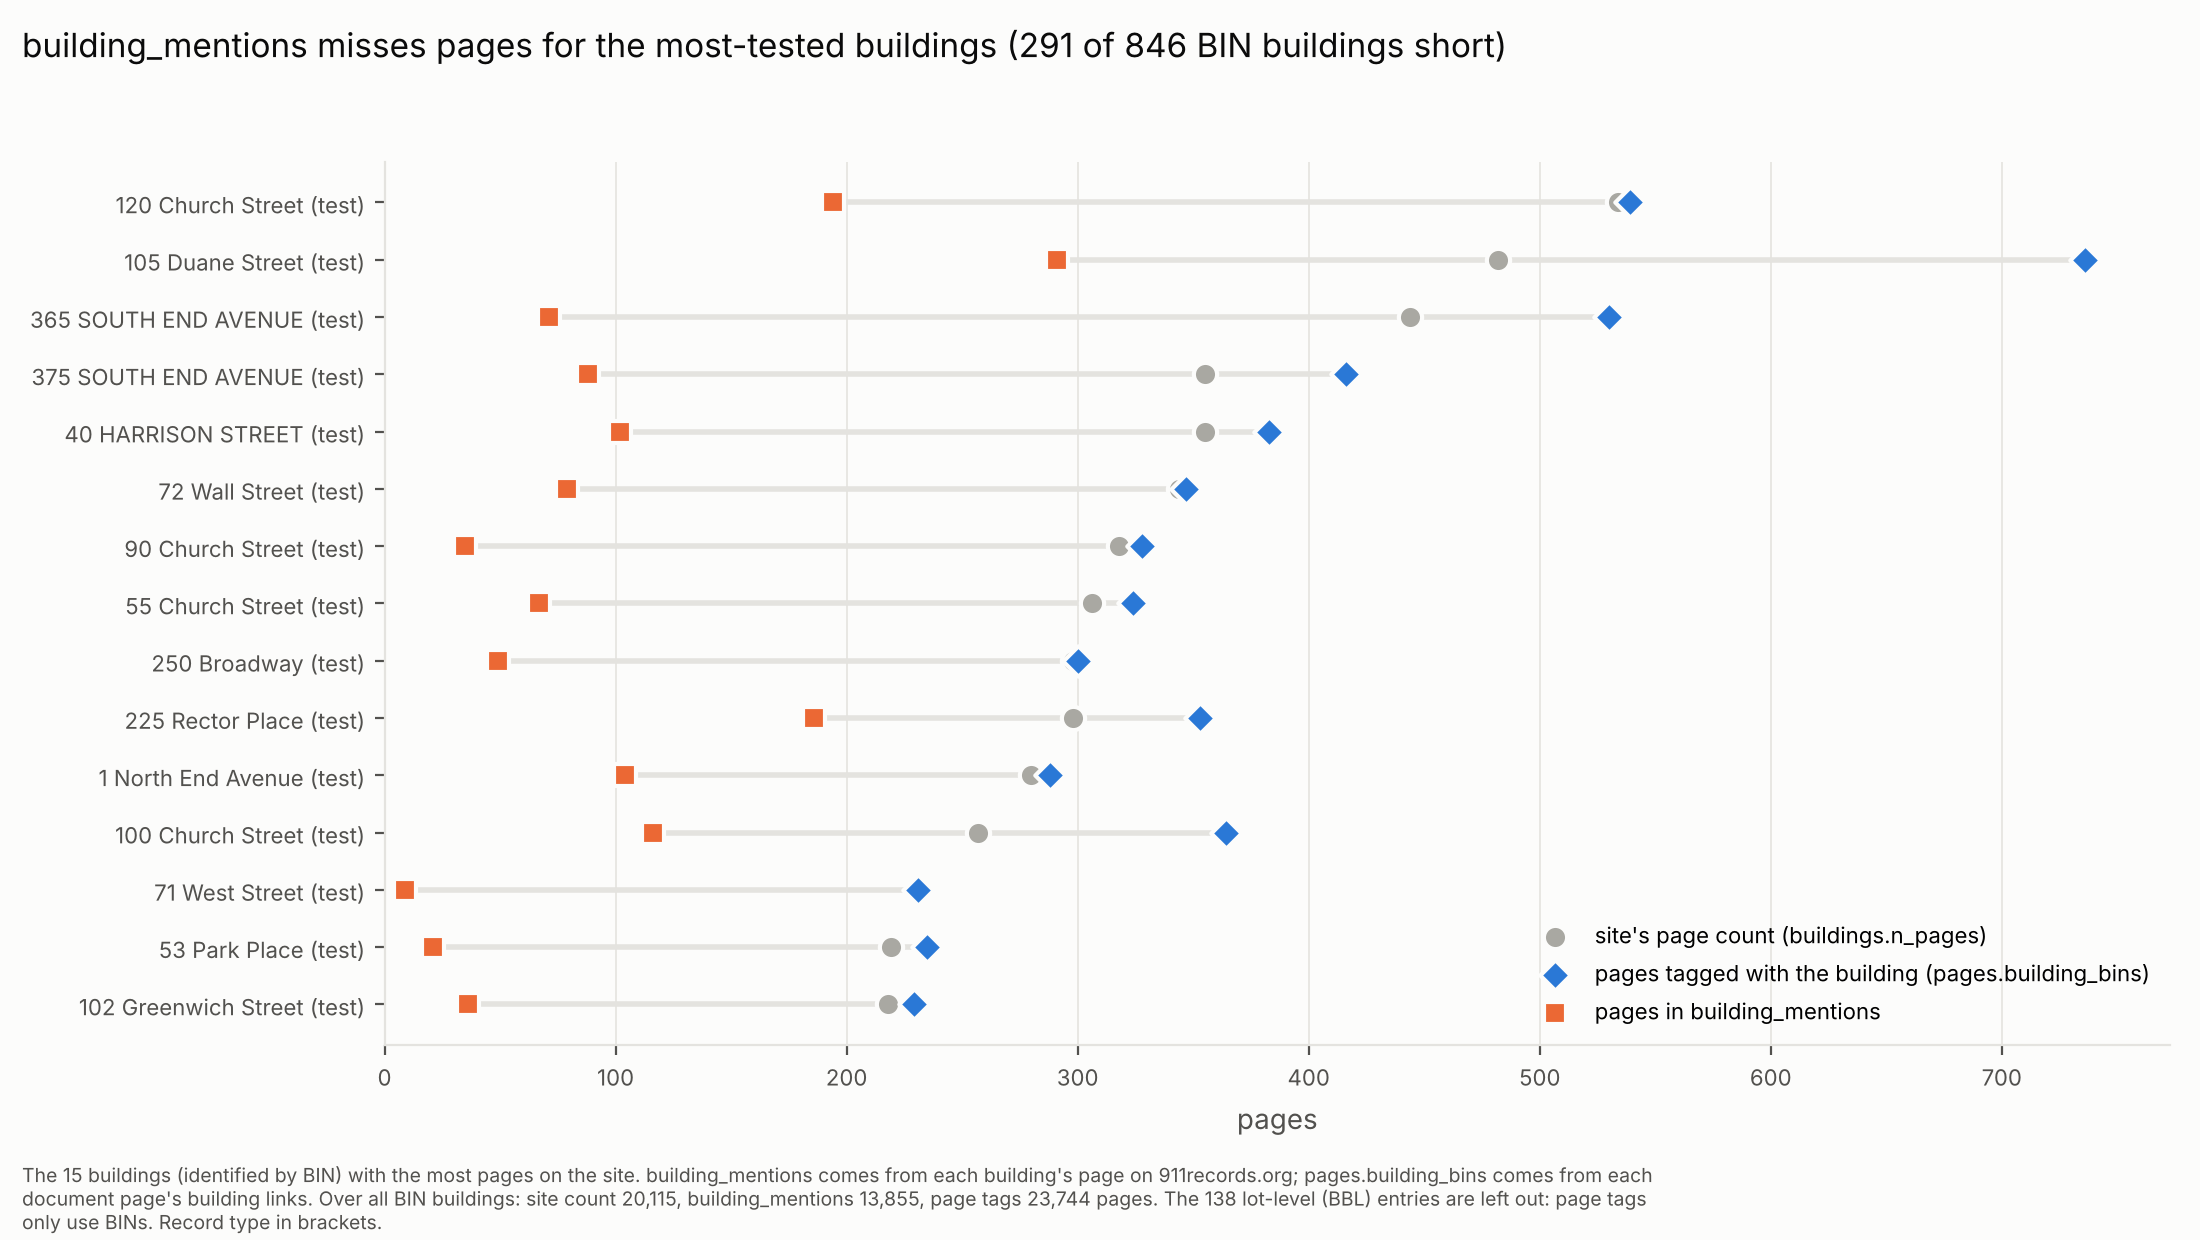

In [15]:
display(Image(str(figures.building_links_figure(cov))))

**Reading.** `building_mentions` holds 13,855 pages for the 846 BIN buildings against 20,115 on the site, and the gap is largest for the most-tested buildings (120 Church Street: 534 on the site, 194 in `building_mentions`, 539 page tags). The page-level tags are close to or above the site's count. The 138 lot (BBL) entries have no page tags by construction. A per-building count of pages or tests should not rely on `building_mentions` alone.

## 8. Catalog changes and ID-only documents

In [16]:
changes = changes.assign(type_from_context=verify.change_type(changes))
print("change column:", changes["change"].value_counts().to_dict())
print(pd.crosstab(changes["capture_date"], changes["type_from_context"]))
changes[["capture_date", "change", "type_from_context", "doc_id", "context"]].head(6)

change column: {'changed': 794}
type_from_context  added  bates range  changed  other
capture_date                                         
2026-09-15             0           30       30      0
2026-10-03             0          188        0      6
2026-10-16           100           85        0      0
2026-10-17             0          190        0      5
2026-10-19           100           60        0      0


,capture_date,change,type_from_context,doc_id,context
0,2026-09-15,changed,changed,NYC-WTC_000003943,"changed GCMS analysis results for sample AE01915 with surrogate data, Mar ↗ NYC-WTC_00..."
1,2026-09-15,changed,bates range,NYC-WTC_000003950,NYC-WTC_000003943 – NYC-WTC_000003950
2,2026-09-15,changed,changed,NYC-WTC_000016872,"changed GCMS analysis report for sample AD30107, January 2002 ↗ NYC-WTC_000016872 – NY..."
3,2026-09-15,changed,bates range,NYC-WTC_000016880,NYC-WTC_000016872 – NYC-WTC_000016880
4,2026-09-15,changed,changed,NYC-WTC_000017192,changed GCMS analysis log for sample AD30608 ↗ NYC-WTC_000017192 – NYC-WTC_000017209 R...
5,2026-09-15,changed,bates range,NYC-WTC_000017209,NYC-WTC_000017192 – NYC-WTC_000017209


In [17]:
ids = verify.id_only_documents(documents)
print(f"document IDs with no metadata, pages or PDF: {len(ids)}; the last page of another document: "
      f"{ids['last_page_of_other'].sum()}; listed in catalog_changes: {ids['doc_id'].isin(changes['doc_id']).sum()}")
example = ids[ids["last_page_of_other"]].iloc[0]["doc_id"]
print("example:", example)
changes[changes["doc_id"] == example][["capture_date", "doc_id", "context"]]

document IDs with no metadata, pages or PDF: 234; the last page of another document: 223; listed in catalog_changes: 223
example: NYC-WTC_000003950


,capture_date,doc_id,context
1,2026-09-15,NYC-WTC_000003950,NYC-WTC_000003943 – NYC-WTC_000003950


**Reading.** The change type was lost: every row says "changed", while the rows' own text says 200 "added" and 30 "changed", so no document can be marked as removed. The parser also read both ends of each Bates range as document IDs; 223 of the 234 ID-only documents are the last page of another document. Both are parser problems, fixable from the cached HTML (report section 6). Until then, count documents that have pages.

## 9. Verification

The same checks as `python -m src.ingestion.verify`. Any failed assertion raises an error; known issues are printed with their counts.

In [18]:
verify.check_text(t)
verify.known_issues(t)

6. text source: pdftotext 230,022, tesseract 865, none 1
7. KNOWN ISSUE: 234 document IDs have no metadata, pages or PDF; 223 of them are the last page of another document
8. KNOWN ISSUE: catalog_changes.change is ['changed']; type from context: bates range 553, added 200, changed 30, other 11
9. KNOWN ISSUE: building_mentions has fewer pages than the site reports for 291 of 846 BIN buildings (13,855 vs 20,115 pages); pages.building_bins tags 23,744


## 10. Summary

| Question | Answer |
| --- | --- |
| Is our copy complete? | Yes: 64,385 documents, all 230,888 pages, entity links equal to the site's counts (3 exceptions explained) |
| Whose files? | 52% of documents are Education's (one-page school air samples); 74% of pages are DEP's |
| Where does the text come from? | the PDFs' own text layer (99.6%); 865 pages by our OCR; 1 empty |
| What needs processing? | dates (20% missing, many wrong), stamps in the text, empty columns, duplicate entity names → `01.process_pipeline.ipynb` |
| What needs fixing in the scrape? | 234 ID-only documents and the lost change type (parser), and `building_mentions` coverage |

Use `data/processed/` for analysis; count documents with pages; for buildings, compare `building_mentions` with `pages.building_bins`.